# 07 · Emoji emotion analysis

Emoji are pulled out with the `emoji` library and put into emotion groups. Several have a sports-specific meaning that a literal reading gets wrong:

* 😂 🤣 are mostly mockery of a team or a take, not happiness.
* 💀 means "dead from laughing" or "this team is finished".
* 🤡 calls a team, a fan base or a take a joke.
* ☘️ 🍊 🐘 🐔 are team symbols (Notre Dame, Tennessee, Alabama, South Carolina).

VADER reads emoji by converting them to their names ("face with tears of joy" → joy), so a mocking 😂 pushes the score *up*. This notebook measures how much.

In [1]:
import sys
import re
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import config

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 110)
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

CREATOR_NAMES = {"pate": "Josh Pate", "crain_cone": "Crain & Cone"}
CREATOR_COLORS = {"Josh Pate": "#1f5fa8", "Crain & Cone": "#d9822b"}
PERIOD_ORDER = ["before", "announcement", "after"]

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

In [2]:
df = pd.read_csv(config.DATA_DIR / "comments_scored.csv", keep_default_na=False,
                 parse_dates=["published_utc", "updated_utc", "video_published_utc"])
df["country"] = df["country"].replace("", np.nan)
df["creator_name"] = df["creator"].map(CREATOR_NAMES)
df.shape

(9456, 37)

In [3]:
# Main score: VADER with the sports word list (chosen with the hand labels in notebook 04).
SCORE, LABEL, SCORE_NAME = "vader_sports_compound", "vader_sports_label", "VADER + sports"

from scipy import stats
import statsmodels.formula.api as smf

def compare(a, b):
    """Welch t-test, Mann-Whitney U and Cohen's d for two score samples."""
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    t, p_t = stats.ttest_ind(b, a, equal_var=False)
    _, p_u = stats.mannwhitneyu(b, a, alternative="two-sided")
    pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return pd.Series({"n_a": len(a), "n_b": len(b), "mean_a": a.mean(), "mean_b": b.mean(),
                      "diff": b.mean() - a.mean(), "cohens_d": (b.mean() - a.mean()) / pooled,
                      "p_welch": p_t, "p_mannwhitney": p_u})

def neg_share(s):
    return (s == "negative").mean()

## Extract emoji

Skin-tone modifiers, variation selectors and joiners are removed so that 🤷🏾‍♂️ and 🤷 count as the same emoji.

In [4]:
import emoji
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

STRIP = re.compile("[\U0001F3FB-\U0001F3FF️‍]")
GENDER = {"♂", "♀"}

def emoji_in(text):
    found = [STRIP.sub("", e["emoji"]) for e in emoji.emoji_list(text)]
    return [e for e in found if e and e not in GENDER]

df["emojis"] = df["text_body"].map(emoji_in)
df["n_emoji"] = df["emojis"].str.len()
df["has_emoji"] = df["n_emoji"] > 0
print(f"Emoji found: {df['n_emoji'].sum():,} in {df['has_emoji'].sum():,} comments ({df['has_emoji'].mean():.1%})")
df.groupby("creator_name")["has_emoji"].mean().round(3).rename("share of comments with emoji")

Emoji found: 1,885 in 983 comments (10.4%)


creator_name
Crain & Cone    0.115
Josh Pate       0.101
Name: share of comments with emoji, dtype: float64

In [5]:
emoji_counts = pd.Series([e for lst in df["emojis"] for e in lst]).value_counts()
top = emoji_counts.head(20)
top.to_frame("count").T

,😂,🤣,😅,🤷,🤡,💯,😭,🎉,☘,🤔,🤘,😢,❤,✌,🍊,🤦,💪,😮,👍,🔥
count,874,122,78,47,44,43,39,32,31,26,26,25,25,23,20,20,19,19,19,19


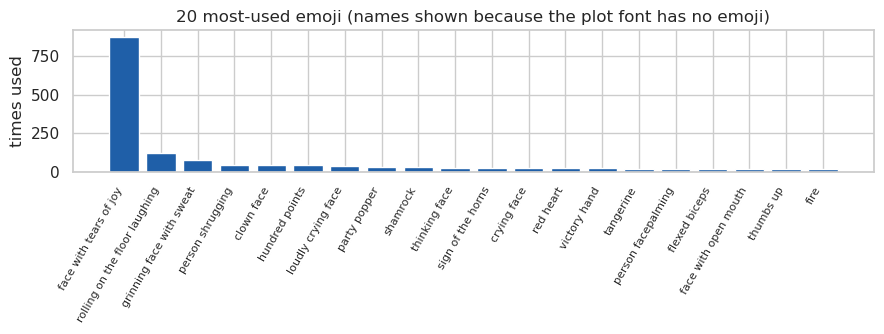

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(len(top)), top.values, color="#1f5fa8")
ax.set_xticks(range(len(top)))
ax.set_xticklabels([emoji.demojize(e).strip(":").replace("_", " ") for e in top.index], rotation=60, ha="right", fontsize=8)
ax.set(ylabel="times used", title="20 most-used emoji (names shown because the plot font has no emoji)")
save(fig, "07_top_emoji.png")

## Emotion groups

In [7]:
EMOTION_GROUPS = {
    "laughter / mockery": "😂🤣😅😆😹😁🤭😝😜",
    "dead / finished":    "💀☠",
    "clown":              "🤡",
    "sad / despair":      "😭😢😩😔💔😞🥲😪😫",
    "anger / disgust":    "😡🤬😤👎🖕🙄🤮💩🗑🚮😒",
    "disbelief":          "🤦🤷🤔🧐😮🤯😬👀🧢😳😱🫠",
    "hype / praise":      "🔥💯💪🙌👏🏆🐐🎉😎🫡🤘✌👍🥶⚡🚀",
    "love / thanks":      "❤💛💙🧡💚💜🖤😍🥰🙏😊😉☺💗❣",
    "team symbol":        "☘🍀🍊🐘🦉🌊🐔🐊🐅🐯🐻🦬🐶🌰🏈🐍🦆🐂🐴🐗",
}
emoji_to_group = {e: grp for grp, chars in EMOTION_GROUPS.items() for e in chars}

def group_of(e):
    return emoji_to_group.get(e, emoji_to_group.get(e[:1], "other"))

ems = (df[df["has_emoji"]].explode("emojis").rename(columns={"emojis": "emoji"})
       [["comment_id", "creator_name", "period", "video_published_utc", "after_announce", "emoji", SCORE, "is_expansion"]])
ems["group"] = ems["emoji"].map(group_of)
group_counts = ems["group"].value_counts()
print(f"Unmapped ('other') share: {group_counts.get('other', 0) / len(ems):.1%}")
print("Most common unmapped:", ems.loc[ems["group"] == "other", "emoji"].value_counts().head(10).to_dict())
group_counts.to_frame("emoji uses")

Unmapped ('other') share: 5.9%
Most common unmapped: {'💰': 5, '🍷': 5, '🏁': 3, '🤪': 3, '👌': 3, '🫵': 3, '🙂': 2, '🟧': 2, '⬜': 2, '💁': 2}


,emoji uses
group,
laughter / mockery,1095
hype / praise,208
disbelief,129
team symbol,122
other,111
love / thanks,68
sad / despair,67
clown,44
anger / disgust,32


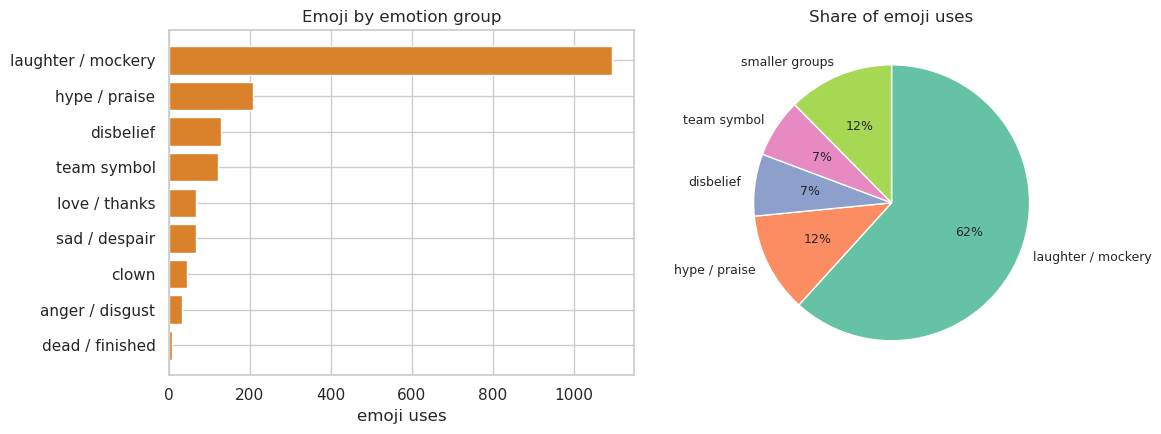

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
gc = group_counts.drop("other", errors="ignore")
axes[0].barh(gc.index[::-1], gc.values[::-1], color="#d9822b")
axes[0].set(xlabel="emoji uses", title="Emoji by emotion group")
small = gc / gc.sum() < 0.04
pie = pd.concat([gc[~small], pd.Series({"smaller groups": gc[small].sum()})])
axes[1].pie(pie.values, labels=pie.index, autopct="%1.0f%%", startangle=90, counterclock=False,
            colors=sns.color_palette("Set2", len(pie)), textprops={"fontsize": 9})
axes[1].set_title("Share of emoji uses")
save(fig, "07_emotion_groups.png")

## Emoji use by creator and period

In [9]:
by_creator = pd.crosstab(ems["group"], ems["creator_name"], normalize="columns").round(3)
by_creator

creator_name,Crain & Cone,Josh Pate
group,,
anger / disgust,0.013,0.018
clown,0.033,0.020
dead / finished,0.000,0.006
disbelief,0.068,0.069
hype / praise,0.157,0.095
laughter / mockery,0.538,0.595
love / thanks,0.050,0.032
other,0.072,0.055
sad / despair,0.039,0.034


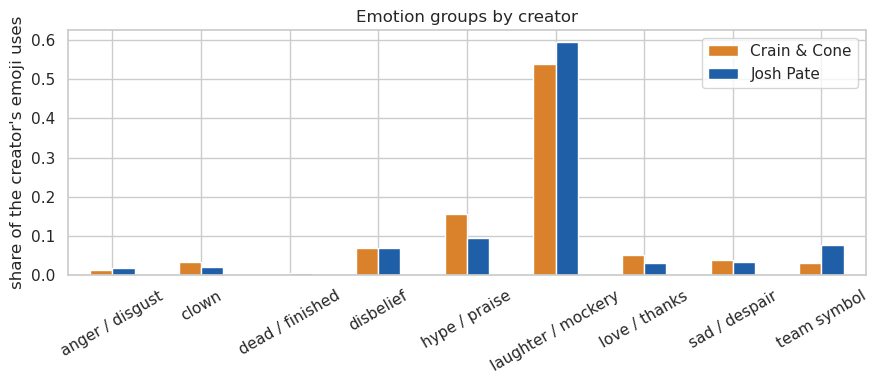

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
by_creator.drop("other", errors="ignore").plot.bar(ax=ax, color=CREATOR_COLORS)
ax.set(xlabel=None, ylabel="share of the creator's emoji uses", title="Emotion groups by creator")
ax.tick_params(axis="x", rotation=30)
ax.legend(title=None)
save(fig, "07_groups_by_creator.png")

In [11]:
by_period = pd.crosstab(ems["group"], ems["period"], normalize="columns")[PERIOD_ORDER].round(3)
by_period

period,before,announcement,after
group,,,
anger / disgust,0.013,0.015,0.025
clown,0.014,0.060,0.034
dead / finished,0.004,0.022,0.002
disbelief,0.059,0.097,0.082
hype / praise,0.132,0.030,0.084
laughter / mockery,0.596,0.418,0.588
love / thanks,0.034,0.052,0.036
other,0.055,0.067,0.064
sad / despair,0.033,0.097,0.027


In [12]:
# Within-video split on pre-announcement videos
pre_e = df[df["video_published_utc"] < config.ANNOUNCE_UTC]
print("Share of comments with any emoji:",
      pre_e.groupby("after_announce")["has_emoji"].mean().rename({False: "before", True: "after"}).round(3).to_dict())
pre_ems = ems[ems["video_published_utc"] < config.ANNOUNCE_UTC]
split = pd.crosstab(pre_ems["group"], pre_ems["after_announce"], normalize="columns").round(3)
split.columns = ["before", "after"]
split

Share of comments with any emoji: {'before': 0.103, 'after': 0.115}


,before,after
group,,
anger / disgust,0.016,0.004
clown,0.017,0.004
dead / finished,0.004,0.004
disbelief,0.058,0.062
hype / praise,0.131,0.136
laughter / mockery,0.613,0.535
love / thanks,0.032,0.043
other,0.047,0.085
sad / despair,0.031,0.039


## How emoji move VADER

Each comment with emoji is scored twice: as written, and with the emoji removed. The difference is the emoji's own contribution to the score. The main score (VADER + sports words) is used; the sports words don't change how VADER reads emoji.

In [13]:
analyzer = SentimentIntensityAnalyzer()
analyzer.lexicon.update(config.SPORTS_LEXICON)       # same scorer as the main score
with_e = df[df["has_emoji"]].copy()
with_e["text_no_emoji"] = with_e["text_body"].map(lambda t: emoji.replace_emoji(t, replace="").strip())
with_e["vader_no_emoji"] = with_e["text_no_emoji"].map(lambda t: analyzer.polarity_scores(t)["compound"])
with_e["emoji_effect"] = with_e[SCORE] - with_e["vader_no_emoji"]

ems = ems.merge(with_e[["comment_id", "emoji_effect", "vader_no_emoji"]], on="comment_id")
effect = (ems.drop_duplicates(["comment_id", "group"]).groupby("group")
          .agg(comments=("comment_id", "size"), score_as_written=(SCORE, "mean"),
               score_without_emoji=("vader_no_emoji", "mean"), emoji_effect=("emoji_effect", "mean"))
          .sort_values("comments", ascending=False))
effect.round(3)

,comments,score_as_written,score_without_emoji,emoji_effect
group,,,,
laughter / mockery,607,0.505,0.066,0.439
hype / praise,114,0.319,0.227,0.093
disbelief,106,0.089,0.057,0.032
other,82,0.241,0.103,0.137
team symbol,53,0.247,0.169,0.078
love / thanks,51,0.654,0.370,0.284
sad / despair,39,-0.287,0.010,-0.297
clown,29,-0.292,0.009,-0.300
anger / disgust,26,0.058,0.036,0.021


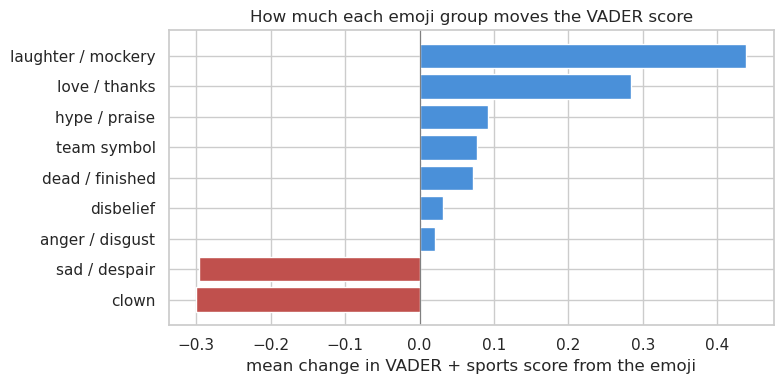

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
e = effect.drop("other", errors="ignore").sort_values("emoji_effect")
ax.barh(e.index, e["emoji_effect"], color=np.where(e["emoji_effect"] > 0, "#4a90d9", "#c0504d"))
ax.axvline(0, color="grey", lw=0.8)
ax.set(xlabel=f"mean change in {SCORE_NAME} score from the emoji", title="How much each emoji group moves the VADER score")
save(fig, "07_emoji_effect_on_vader.png")

In [15]:
print("Laughter / mockery comments that the main score rates clearly positive (> 0.5), for a manual look:")
laugh_ids = ems.loc[ems["group"] == "laughter / mockery", "comment_id"].unique()
sample = with_e[with_e["comment_id"].isin(laugh_ids) & (with_e[SCORE] > 0.5)]
print(f"{len(sample)} of {len(laugh_ids)} laughter comments")
sample[["text_body", SCORE, "vader_no_emoji"]].sample(10, random_state=1).round(2)

Laughter / mockery comments that the main score rates clearly positive (> 0.5), for a manual look:
356 of 607 laughter comments


,text_body,vader_sports_compound,vader_no_emoji
7971,"The Little 10 sux this year, get over it 😅😅😅",0.65,-0.30
4008,David Talk about Texas great losses vs OU and Fkorida 😂,0.65,0.34
2354,"the same Texas team that has wins against OSU, Tennessee, Ole Miss, and Missouri currently? Please explain...",0.97,0.96
2636,😂😂 and yet we all still watch…. Wait when its a 24 team playoff some will advocate for the entire SEC to m...,0.70,0.00
2549,41-28 🤣🤣 Jesse needs a strong tongue lashing,0.87,0.51
8826,They’re going into more contortions but the bias still shows😂😂😂,0.90,-0.15
8936,because Keelon is better lol. Austin Mack would 100% start at Tennessee. Easily. Y’all are so dumb 😂 none ...,0.71,0.45
4081,PLEASE CONTINUE TO USE THE SOUND BOARD EVERY EPISODE LOL😂🔥,0.79,0.62
4671,what happen to Bama and rest of SEC teams last year when they played Miami?\nIf they are using Mississippi...,0.81,0.62
4285,Ask Holly Rowe if she thinks Texas should be in there. 🤣🤣🤣,0.86,0.00


In [16]:
df[["comment_id", "emojis"]].assign(emojis=df["emojis"].str.join(" ")).to_csv(
    config.DATA_DIR / "comment_emoji.csv", index=False)
print("saved data/comment_emoji.csv")

saved data/comment_emoji.csv
